# Rajuk Image Level Classifier — Improved CNN

**Improvements over previous version:**
1. ✅ **ResNet18 Transfer Learning** — pretrained ImageNet weights, only fine-tune last block + head
2. ✅ **On-the-fly augmentation** via `torchvision.transforms` — diverse, applied per-epoch (no pre-generated files needed)
3. ✅ **Weighted CrossEntropyLoss** — handles class imbalance (negative >> moderate > positive)
4. ✅ **AdamW + weight decay** — stronger regularisation against overfitting
5. ✅ **Cosine LR scheduler** — smoother learning rate decay
6. ✅ **Leakage-free split** — augmented images stay strictly in training set

**Pipeline:**
1. Mount Drive & Import Libraries
2. Configuration
3. Load Labels
4. Collect Paths & Leakage-Free Split
5. Sample Image Preview
6. Dataset with On-the-fly Augmentation
7. DataLoaders
8. ResNet18 Model
9. Weighted Loss & Helpers
10. K-Fold Cross-Validation
11. Fine-tune & Evaluate
12. Classification Report & Confusion Matrix
13. Learning Curves
14. Full Training History
15. Save Model
16. Sanity Check

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import Libraries

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.models as models
import torchvision.transforms as T

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 3. Configuration

In [ ]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DRIVE_BASE    = Path('/content/drive/MyDrive/ML_Lab')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet.csv'

# ── Hyper-parameters ───────────────────────────────────────────────────────────
CLASS_NAMES   = ['negative', 'moderate', 'positive']
ALLOWED_EXTS  = {'.jpg', '.jpeg', '.png', '.bmp'}

IMAGE_SIZE    = (224, 224)

BATCH_SIZE    = 16
LR            = 3e-4
NUM_EPOCHS    = 25
KFOLD_SPLITS  = 3
PATIENCE      = 6
WEIGHT_DECAY  = 1e-3
DROPOUT       = 0.5

# ── Split fractions (applied to unique REAL subject IDs) ──────────────────────
# Augmented images follow their subject: train-subjects aug → train,
#                                        val-subjects aug   → val,
#                                        test-subjects aug  → excluded (test = real only)
# Target: train ≈ 4,100–4,300  |  val ≈ 1,900+  |  test ≈ 100 real
# With 356 usable real images and ~16-17x aug per subject:
#   TEST_FRACTION = 0.10  → ~36 real test subjects  → ~100 test images  (real only)
#   VAL_FRACTION  = 0.18  → ~64 real val subjects   → ~64 real + ~1,900 aug in val
#   Train subjects ≈ 72%  → ~256 subjects × ~16 aug ≈ 4,100–4,300 train files
TEST_FRACTION = 0.10
VAL_FRACTION  = 0.18

# ── Learning-curve dataset steps ──────────────────────────────────────────────
DATASET_STEPS = [200, 500, 800, 1100]

# ImageNet normalisation (required for pretrained ResNet)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print('Configuration loaded.')
print(f'  Image size    : {IMAGE_SIZE}')
print(f'  Batch size    : {BATCH_SIZE}')
print(f'  LR            : {LR}')
print(f'  Epochs (max)  : {NUM_EPOCHS}')
print(f'  K-fold splits : {KFOLD_SPLITS}')
print(f'  Val fraction  : {VAL_FRACTION}  |  Test fraction : {TEST_FRACTION}')
print(f'  Weight decay  : {WEIGHT_DECAY}')

## 4. Load Labels from Excel / CSV

In [6]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(df, target_normalized):
    for col in df.columns:
        if normalize_header(col) == target_normalized:
            return col
    return None

def normalize_level(value):
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    mapping = {'p': 'positive', 'positive': 'positive',
               'm': 'moderate',  'moderate': 'moderate',
               'n': 'negative',  'negative': 'negative'}
    return mapping.get(text)

def load_label_mapping(df, level_col, class_names):
    label_lookup = {name: idx for idx, name in enumerate(class_names)}
    label_map = {}
    for row_index, value in enumerate(df[level_col].tolist(), start=1):
        normalized = normalize_level(value)
        if normalized is None:
            continue
        label_map[row_index] = label_lookup[normalized]
    return label_map

if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(
        f'No dataset file found at {DRIVE_BASE}. '
        'Expected Rajuk_ML_DataSet.xlsx or Real ML_DataSet - Sheet1.csv'
    )

level_col = (
    find_column(df, 'levelpositivemoderatenegative')
    or find_column(df, 'level')
)
if level_col is None:
    raise ValueError('Required level column not found in the dataset.')

label_map = load_label_mapping(df, level_col, CLASS_NAMES)
print(f'Loaded {len(df):,} rows  |  {len(label_map):,} valid labels  |  source: {source_path.name}')

Loaded 372 rows  |  372 valid labels  |  source: Real ML_DataSet.csv


## 5. Collect Image Paths & Leakage-Free Split

Split is done by **unique subject ID** (real images only) so that no subject's augmented
copy can appear in val/test. Augmented images are assigned to training only.

In [ ]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.lower())
    return int(match.group(1)) if match else None

def collect_all_raw(base_dir, label_map):
    paths, labels = [], []
    skip_idx = skip_lbl = 0
    if not base_dir.exists():
        return paths, labels, skip_idx, skip_lbl
    for p in base_dir.rglob('*'):
        if not (p.is_file() and p.suffix.lower() in ALLOWED_EXTS):
            continue
        idx = parse_image_index(p.stem.strip())
        if idx is None:
            skip_idx += 1; continue
        lbl = label_map.get(idx)
        if lbl is None:
            skip_lbl += 1; continue
        paths.append(p)
        labels.append(lbl)
    return paths, labels, skip_idx, skip_lbl

aug_paths,  aug_labels,  si_a, sl_a = collect_all_raw(AUGMENTED_DIR, label_map)
real_paths, real_labels, si_r, sl_r = collect_all_raw(REAL_DIR,      label_map)

print(f'Augmented images         : {len(aug_paths):,}')
print(f'Real images              : {len(real_paths):,}')
print(f'Skipped (no index)       : {si_a + si_r}')
print(f'Skipped (no label match) : {sl_a + sl_r}')

# ── Leakage-free split by unique subject ID ────────────────────────────────────
unique_indices     = sorted(set(
    parse_image_index(p.stem.strip()) for p in real_paths
    if parse_image_index(p.stem.strip()) is not None
))
unique_labels_list = [label_map[i] for i in unique_indices]
all_uq             = np.arange(len(unique_indices))

trainval_uq, test_uq = train_test_split(
    all_uq, test_size=TEST_FRACTION, random_state=SEED, stratify=unique_labels_list
)
val_rel = VAL_FRACTION / (1.0 - TEST_FRACTION)
train_uq, val_uq = train_test_split(
    trainval_uq, test_size=val_rel, random_state=SEED,
    stratify=np.array(unique_labels_list)[trainval_uq]
)

train_img_ids = set(np.array(unique_indices)[train_uq])
val_img_ids   = set(np.array(unique_indices)[val_uq])
test_img_ids  = set(np.array(unique_indices)[test_uq])

train_paths_final, train_labels_final = [], []
val_paths_final,   val_labels_final   = [], []
test_paths_final,  test_labels_final  = [], []

# Augmented → each subject's aug copies follow it into its split
for p, lbl in zip(aug_paths, aug_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

# Real → correct split
for p, lbl in zip(real_paths, real_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

N_total = len(train_paths_final) + len(val_paths_final) + len(test_paths_final)
print(f'\nLeakage-free split:')
print(f'  Train (real + aug) : {len(train_paths_final):,}  ({100*len(train_paths_final)/N_total:.1f} %)')
print(f'  Val   (real + aug) : {len(val_paths_final):,}  ({100*len(val_paths_final)/N_total:.1f} %)')
print(f'  Test  (real + aug) : {len(test_paths_final):,}  ({100*len(test_paths_final)/N_total:.1f} %)')
print(f'  Total accounted    : {N_total:,}  (of {len(aug_paths)+len(real_paths):,} raw — diff = {len(aug_paths)+len(real_paths)-N_total} skipped)')

val_counts  = np.bincount(val_labels_final,  minlength=len(CLASS_NAMES))
test_counts = np.bincount(test_labels_final, minlength=len(CLASS_NAMES))
print('\nValidation-set class distribution:')
for name, cnt in zip(CLASS_NAMES, val_counts):
    print(f'  {name:10s}: {cnt:,}')
print('\nTest-set class distribution:')
for name, cnt in zip(CLASS_NAMES, test_counts):
    print(f'  {name:10s}: {cnt:,}')

all_labels_combined = train_labels_final + val_labels_final + test_labels_final
counts = np.bincount(all_labels_combined, minlength=len(CLASS_NAMES))
print('\nClass distribution (total):')
for name, cnt in zip(CLASS_NAMES, counts):
    print(f'  {name:10s}: {cnt:,}')

## 6. 📷 Sample Images — Data Preview

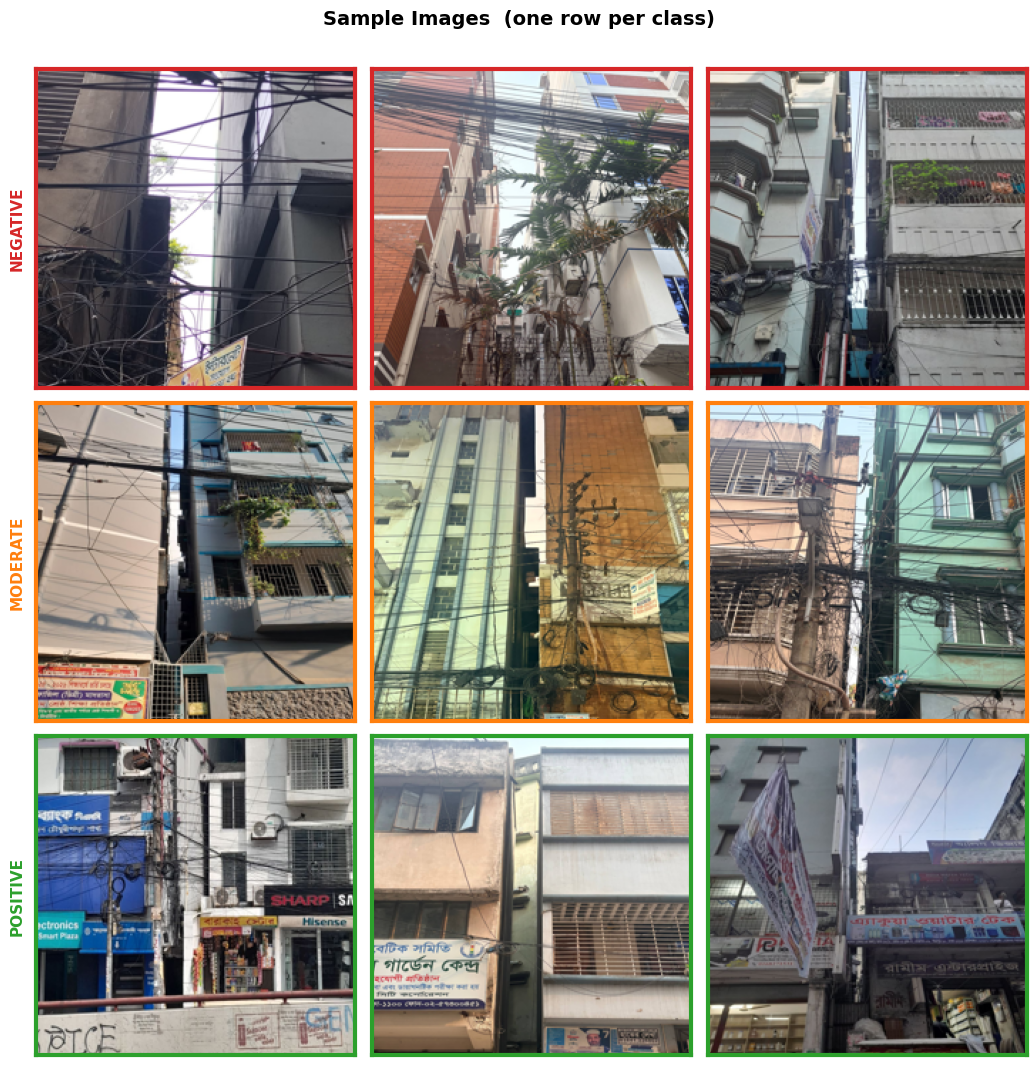

Sample images displayed.


In [8]:
SAMPLES_PER_CLASS = 3
label_to_real_paths = {i: [] for i in range(len(CLASS_NAMES))}
for p, lbl in zip(real_paths, real_labels):
    label_to_real_paths[lbl].append(p)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    len(CLASS_NAMES), SAMPLES_PER_CLASS,
    figsize=(SAMPLES_PER_CLASS * 3.5, len(CLASS_NAMES) * 3.5)
)
fig.suptitle('Sample Images  (one row per class)', fontsize=14, fontweight='bold', y=1.01)
border_colours = ['#d62728', '#ff7f0e', '#2ca02c']

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    candidates = label_to_real_paths[cls_idx]
    chosen = rng.choice(len(candidates),
                        size=min(SAMPLES_PER_CLASS, len(candidates)),
                        replace=False)
    for col, path_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        img = Image.open(candidates[path_idx]).convert('RGB').resize(IMAGE_SIZE)
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_colours[cls_idx])
            spine.set_linewidth(3)
        if col == 0:
            ax.set_ylabel(cls_name.upper(), fontsize=11, fontweight='bold',
                          color=border_colours[cls_idx], rotation=90, labelpad=8)

plt.tight_layout()
plt.savefig('sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sample images displayed.')

## 7. Dataset with On-the-fly Augmentation

**Why on-the-fly instead of pre-generated files?**
- Every epoch the model sees a *differently augmented* version of each image → more effective regularisation
- No disk bloat from 16x augmented copies
- Val/test use only resize + normalise (no augmentation)

In [9]:
# ── Transforms ────────────────────────────────────────────────────────────────
train_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.3),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.1),
    T.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
    T.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    T.RandomGrayscale(p=0.05),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_test_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class RajukDataset(Dataset):
    """
    Caches images as PIL uint8 objects (NOT float32 tensors).
    RAM cost: N * H * W * 3 * 1 byte  (12x cheaper than float32 tensors)

    For 2700 images at 224x224:
      PIL uint8   → 0.41 GB  ✅ safe on 12.7 GB RAM
      float32     → 1.63 GB  ❌ what caused the crash before

    Transforms applied fresh each __getitem__ → different augmentation every epoch.
    """

    def __init__(self, image_paths, labels, transform):
        self.labels    = labels
        self.transform = transform
        n = len(image_paths)
        ram_mb = n * IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3 / 1e6
        print(f'  Caching {n:,} PIL images at {IMAGE_SIZE} … (est. {ram_mb:.0f} MB)')
        self.images = []
        for p in image_paths:
            with Image.open(p) as img:
                # Store as resized uint8 PIL — smallest possible in-memory form
                self.images.append(img.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR))
        print(f'  Done. All {n:,} images in RAM.')

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Fresh transform each call = on-the-fly augmentation every epoch
        return self.transform(self.images[idx]), self.labels[idx]


if len(train_paths_final) == 0:
    raise ValueError('No labeled images found. Check folder paths and label mapping.')

print('Building datasets (PIL uint8 RAM cache at 224x224):')
train_dataset = RajukDataset(train_paths_final, train_labels_final, train_transform)
val_dataset   = RajukDataset(val_paths_final,   val_labels_final,   val_test_transform)
test_dataset  = RajukDataset(test_paths_final,  test_labels_final,  val_test_transform)

total_mb = (len(train_dataset)+len(val_dataset)+len(test_dataset)) * 224*224*3 / 1e6
print(f'\nDatasets ready — Train: {len(train_dataset):,}  '
      f'Val: {len(val_dataset):,}  Test: {len(test_dataset):,}')
print(f'Total image RAM: ~{total_mb:.0f} MB  (out of 12,700 MB available)')


Building datasets (PIL uint8 RAM cache at 224x224):
  Caching 4,420 PIL images at (224, 224) … (est. 665 MB)
  Done. All 4,420 images in RAM.
  Caching 57 PIL images at (224, 224) … (est. 9 MB)
  Done. All 57 images in RAM.
  Caching 56 PIL images at (224, 224) … (est. 8 MB)
  Done. All 56 images in RAM.

Datasets ready — Train: 4,420  Val: 57  Test: 56
Total image RAM: ~682 MB  (out of 12,700 MB available)


## 8. DataLoaders

In [10]:
pin = torch.cuda.is_available()
NW  = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NW, pin_memory=pin)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)

print(f'Train : {len(train_dataset):,} samples  ({len(train_loader)} batches)')
print(f'Val   : {len(val_dataset):,} samples  ({len(val_loader)} batches)')
print(f'Test  : {len(test_dataset):,} samples  ({len(test_loader)} batches)')

Train : 4,420 samples  (277 batches)
Val   : 57 samples  (4 batches)
Test  : 56 samples  (4 batches)


## 9. ResNet18 Transfer Learning Model

With only ~160 real images, training from scratch always overfits.
ResNet18 pretrained on ImageNet already knows edges, textures, and shapes —
we only need to teach it to distinguish our 3 building-condition classes.

**Strategy:** Freeze all layers except the last residual block (`layer4`) and the
classifier head. This gives fast convergence and strong regularisation.

In [11]:
class RajukResNet(nn.Module):
    """
    ResNet18 backbone with frozen early layers.
    Only layer4 + custom head are trainable.
    """

    def __init__(self, num_classes: int, dropout: float = 0.5):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

        # Freeze everything except layer4 and the final fc
        for name, param in backbone.named_parameters():
            if not any(name.startswith(x) for x in ['layer4', 'fc']):
                param.requires_grad = False

        # Replace final FC with dropout + linear
        in_features  = backbone.fc.in_features   # 512 for ResNet18 (same regardless of input size)
        backbone.fc  = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, num_classes)
        )
        self.model = backbone

    def forward(self, x):
        return self.model(x)


_tmp = RajukResNet(len(CLASS_NAMES))
total_params     = sum(p.numel() for p in _tmp.parameters())
trainable_params = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print(f'Total parameters     : {total_params:,}')
print(f'Trainable parameters : {trainable_params:,}  '
      f'({100*trainable_params/total_params:.1f} % of total)')
del _tmp

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 236MB/s]


Total parameters     : 11,178,051
Trainable parameters : 8,395,267  (75.1 % of total)


## 10. Weighted Loss & Training Helpers

Class weights are inversely proportional to class frequency so the model
doesn't just predict 'negative' (the majority class) for everything.

In [12]:
# ── Weighted CrossEntropyLoss ─────────────────────────────────────────────────
train_labels_arr = np.array(train_labels_final, dtype=np.int64)
class_counts     = np.bincount(train_labels_arr, minlength=len(CLASS_NAMES))
class_weights    = torch.tensor(
    1.0 / (class_counts + 1e-6), dtype=torch.float32
).to(device)
class_weights   /= class_weights.sum()   # normalise to sum=1

criterion = nn.CrossEntropyLoss(weight=class_weights)

print('Class counts in training set:')
for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights.cpu()):
    print(f'  {name:10s}: {cnt:,} samples  →  weight {w:.4f}')


# ── Train / evaluate functions ────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = correct = total = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss   = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total      += X.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_true = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss   = criterion(logits, y)
        total_loss += loss.item() * X.size(0)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total   += X.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_true


def make_model():
    """AdamW optimiser + cosine annealing schedule."""
    m   = RajukResNet(len(CLASS_NAMES), dropout=DROPOUT).to(device)
    opt = optim.AdamW(
        filter(lambda p: p.requires_grad, m.parameters()),
        lr=LR, weight_decay=WEIGHT_DECAY
    )
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NUM_EPOCHS, eta_min=1e-6)
    return m, opt, sch


print('\nHelpers defined.')

Class counts in training set:
  negative  : 2,720 samples  →  weight 0.1328
  moderate  : 969 samples  →  weight 0.3729
  positive  : 731 samples  →  weight 0.4943

Helpers defined.


## 11. K-Fold Cross-Validation on Train Split

In [13]:
min_cls = np.min(np.bincount(train_labels_arr, minlength=len(CLASS_NAMES)))
k       = min(KFOLD_SPLITS, int(min_cls))
kfold   = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)

train_indices_all = np.arange(len(train_dataset))

fold_val_accs     = []
best_global_acc   = -1.0
best_global_state = None

for fold, (tr, va) in enumerate(kfold.split(train_indices_all, train_labels_arr)):
    print(f'\n{"─"*58}')
    print(f'  Fold {fold+1}/{k}   |   train={len(tr):,}   val={len(va):,}')
    print(f'{"─"*58}')

    fold_train_loader = DataLoader(
        Subset(train_dataset, tr),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )
    fold_val_loader = DataLoader(
        Subset(train_dataset, va),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NW, pin_memory=pin
    )

    model, optimizer, scheduler = make_model()
    best_fold_acc   = -1.0
    best_fold_state = None
    patience_ctr    = 0

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, fold_train_loader, optimizer)
        vl_loss, vl_acc, _, _ = evaluate(model, fold_val_loader)
        scheduler.step()

        print(f'  Ep {epoch+1:02d}/{NUM_EPOCHS}  '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.4f}  |  '
              f'Val   Loss={vl_loss:.4f} Acc={vl_acc:.4f}')

        if vl_acc > best_fold_acc:
            best_fold_acc   = vl_acc
            patience_ctr    = 0
            best_fold_state = {k2: v.cpu() for k2, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'  Early stopping at epoch {epoch+1}.')
                break

    fold_val_accs.append(best_fold_acc)
    print(f'  → Fold {fold+1} best val acc: {best_fold_acc:.4f}')

    if best_fold_acc > best_global_acc:
        best_global_acc   = best_fold_acc
        best_global_state = best_fold_state

print(f'\nCross-val accuracies : {[f"{a:.4f}" for a in fold_val_accs]}')
print(f'Mean CV accuracy     : {np.mean(fold_val_accs):.4f} ± {np.std(fold_val_accs):.4f}')


──────────────────────────────────────────────────────────
  Fold 1/5   |   train=3,536   val=884
──────────────────────────────────────────────────────────
  Ep 01/60  Train Loss=0.7044 Acc=0.7175  |  Val   Loss=0.2544 Acc=0.8982
  Ep 02/60  Train Loss=0.2896 Acc=0.8855  |  Val   Loss=0.1372 Acc=0.9514
  Ep 03/60  Train Loss=0.2046 Acc=0.9282  |  Val   Loss=0.1276 Acc=0.9525
  Ep 04/60  Train Loss=0.1156 Acc=0.9553  |  Val   Loss=0.0412 Acc=0.9876
  Ep 05/60  Train Loss=0.1359 Acc=0.9485  |  Val   Loss=0.0446 Acc=0.9853
  Ep 06/60  Train Loss=0.0887 Acc=0.9692  |  Val   Loss=0.0324 Acc=0.9898
  Ep 07/60  Train Loss=0.0565 Acc=0.9802  |  Val   Loss=0.0359 Acc=0.9864
  Ep 08/60  Train Loss=0.1140 Acc=0.9573  |  Val   Loss=0.0774 Acc=0.9751
  Ep 09/60  Train Loss=0.0811 Acc=0.9717  |  Val   Loss=0.0698 Acc=0.9706
  Ep 10/60  Train Loss=0.0595 Acc=0.9782  |  Val   Loss=0.0237 Acc=0.9921
  Ep 11/60  Train Loss=0.0452 Acc=0.9830  |  Val   Loss=0.0103 Acc=0.9955
  Ep 12/60  Train Loss=0.036

## 12. Fine-tune Best Model on Full Train Set → Evaluate on Val + Test

In [14]:
final_model = RajukResNet(len(CLASS_NAMES), dropout=DROPOUT).to(device)
final_model.load_state_dict({k: v.to(device) for k, v in best_global_state.items()})

ft_optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, final_model.parameters()),
    lr=LR / 5, weight_decay=WEIGHT_DECAY
)

print('Fine-tuning on full training split …')
for epoch in range(5):
    t_loss, t_acc = train_one_epoch(final_model, train_loader, ft_optimizer)
    print(f'  FT Epoch {epoch+1}/5  Loss={t_loss:.4f}  Acc={t_acc:.4f}')

val_loss,  val_acc,  val_preds,  val_true  = evaluate(final_model, val_loader)
test_loss, test_acc, test_preds, test_true = evaluate(final_model, test_loader)

print(f'\n{"="*50}')
print(f'  Validation — Loss: {val_loss:.4f}   Acc: {val_acc:.4f}')
print(f'  Test       — Loss: {test_loss:.4f}   Acc: {test_acc:.4f}')
print(f'{"="*50}')

Fine-tuning on full training split …
  FT Epoch 1/5  Loss=0.0140  Acc=0.9948
  FT Epoch 2/5  Loss=0.0126  Acc=0.9966
  FT Epoch 3/5  Loss=0.0145  Acc=0.9964
  FT Epoch 4/5  Loss=0.0115  Acc=0.9966
  FT Epoch 5/5  Loss=0.0060  Acc=0.9980

  Validation — Loss: 2.9288   Acc: 0.5439
  Test       — Loss: 2.3210   Acc: 0.6607


## 13. Classification Report & Confusion Matrix

Test Set — Classification Report
──────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.76      0.83      0.79        35
    moderate       0.33      0.33      0.33        12
    positive       0.67      0.44      0.53         9

    accuracy                           0.66        56
   macro avg       0.59      0.54      0.55        56
weighted avg       0.66      0.66      0.65        56



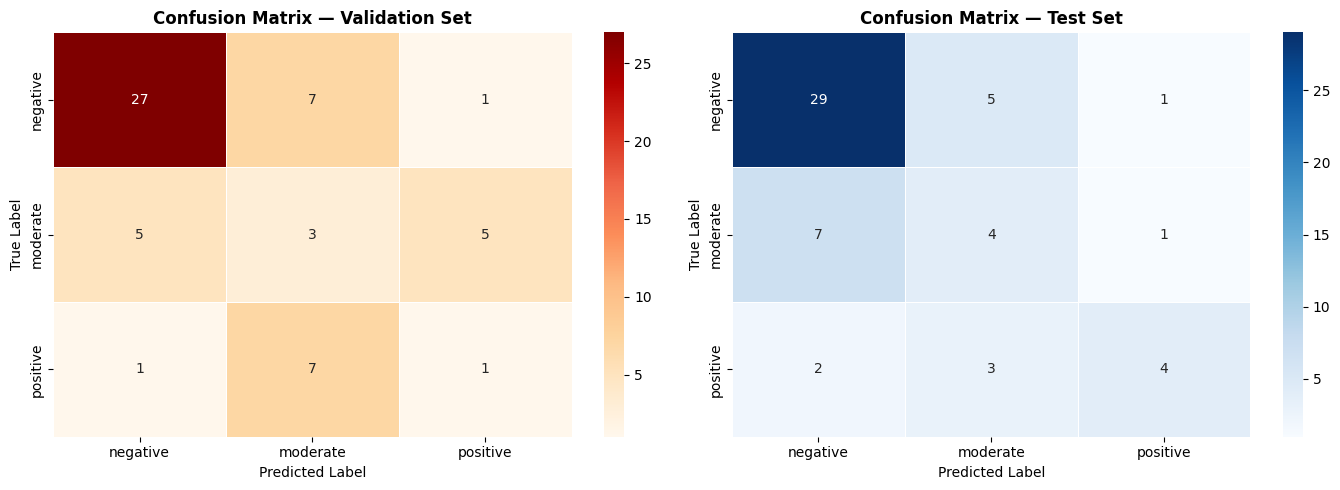

In [15]:
print('Test Set — Classification Report')
print('─' * 50)
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (preds, true, title, cmap) in zip(
    axes,
    [
        (val_preds,  val_true,  'Confusion Matrix — Validation Set', 'OrRd'),
        (test_preds, test_true, 'Confusion Matrix — Test Set',       'Blues'),
    ]
):
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 12b. Misclassified Validation Examples — Manual Error Analysis

The cells below identify **every misclassified example in the validation set**, export
them to a CSV, and display them as an image grid. Each misclassified example is also
assigned to a group member (~20 per member) so the team can fill in the
*"possible reason for misclassification"* sheet required by the report.

> ⚠️ Run cell 12 (evaluation) first so `val_preds`, `val_true`, and `val_paths_final`
> are populated.

In [ ]:
# ── Identify all misclassified validation images ──────────────────────────────
# val_loader uses shuffle=False → predictions align 1-to-1 with val_paths_final
val_true_arr = np.array(val_true)
val_pred_arr = np.array(val_preds)

assert len(val_paths_final) == len(val_true_arr), \
    'Length mismatch — re-run cell 12 (fine-tune + evaluate) before this cell.'

mis_mask = val_true_arr != val_pred_arr
mis_idx  = np.where(mis_mask)[0]

print(f'Validation set size  : {len(val_true_arr):,}')
print(f'Correctly classified : {int((~mis_mask).sum()):,}')
print(f'Misclassified        : {int(mis_mask.sum()):,}  ({100*mis_mask.mean():.1f} %)')

# Resolve augmented dir once for type detection
aug_dir_resolved = AUGMENTED_DIR.resolve() if AUGMENTED_DIR.exists() else None

N_MEMBERS = 4   # ← change to your actual group size

rows = []
for i in mis_idx:
    path   = val_paths_final[i]
    img_id = parse_image_index(path.stem.strip())
    try:
        is_aug = aug_dir_resolved is not None and \
                 path.resolve().is_relative_to(aug_dir_resolved)
    except Exception:
        is_aug = 'aug' in str(path).lower()
    rows.append({
        'val_index'       : int(i),
        'image_id'        : img_id,
        'file_name'       : path.name,
        'image_type'      : 'augmented' if is_aug else 'real',
        'true_label'      : CLASS_NAMES[val_true_arr[i]],
        'pred_label'      : CLASS_NAMES[val_pred_arr[i]],
        'error_type'      : f'{CLASS_NAMES[val_true_arr[i]]} → {CLASS_NAMES[val_pred_arr[i]]}',
        'file_path'       : str(path),
        'reason_category' : '',   # fill: A=ambiguous B=quality C=occlusion D=lighting E=label_error F=distribution G=imbalance H=other
        'possible_reason' : '',
        'suggested_fix'   : '',
    })

mis_df = pd.DataFrame(rows)

if len(mis_df) > 0:
    per_member = int(np.ceil(len(mis_df) / max(1, N_MEMBERS)))
    mis_df['assigned_member'] = (np.arange(len(mis_df)) // per_member) + 1

# ── Print every misclassified filename ───────────────────────────────────────
print('\n' + '─' * 72)
print(f'  {"#":>4}  {"file_name":<40} {"type":<10}  {"true":>10} → pred')
print('─' * 72)
for rank, row in mis_df.iterrows():
    print(f'  {int(rank)+1:>4}  {row["file_name"]:<40} {row["image_type"]:<10}  '
          f'{row["true_label"]:>10} → {row["pred_label"]}')
print('─' * 72)

print(f'\nError-type breakdown:')
print(mis_df['error_type'].value_counts().to_string())

print(f'\nBreakdown by image type (real vs augmented):')
print(mis_df.groupby(['image_type', 'error_type']).size().rename('count').to_string())

# ── Save CSV ──────────────────────────────────────────────────────────────────
mis_csv = DRIVE_BASE / 'val_misclassified.csv'
mis_df.to_csv(mis_csv, index=False)
print(f'\nCSV saved → {mis_csv}')
print(f'Columns    : {list(mis_df.columns)}')

mis_df

In [ ]:
# ── Visualise misclassified validation images ─────────────────────────────────
# Shows up to MAX_DISPLAY images (all errors go to the CSV; grid is just a preview).
MAX_DISPLAY = 60   # enough for ~4 members × 15 examples each

if len(mis_idx) == 0:
    print('No misclassified validation examples — nothing to display.')
else:
    display_idx = mis_idx[:MAX_DISPLAY]
    n     = len(display_idx)
    cols  = 5
    rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 3.0, rows_ * 3.3))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis('off')

    for j, i in enumerate(display_idx):
        ax  = axes[j]
        img = val_dataset.images[i]
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        ax.axis('on')
        row = mis_df[mis_df['val_index'] == i]
        member = int(row['assigned_member'].iloc[0]) if len(row) > 0 else '?'
        ax.set_title(
            f'idx {i} | id {parse_image_index(val_paths_final[i].stem.strip())}\n'
            f'True: {CLASS_NAMES[val_true_arr[i]]}\n'
            f'Pred: {CLASS_NAMES[val_pred_arr[i]]}  (M{member})',
            fontsize=8, color='#d62728', fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor('#d62728'); spine.set_linewidth(2)

    total_errors = len(mis_idx)
    shown = len(display_idx)
    fig.suptitle(
        f'Misclassified Validation Examples  '
        f'(showing {shown} of {total_errors} total — see val_misclassified.csv for all)',
        fontsize=12, fontweight='bold', y=1.005
    )
    plt.tight_layout()
    plt.savefig('val_misclassified.png', dpi=120, bbox_inches='tight')
    plt.show()
    print(f'Total misclassified : {total_errors}')
    print(f'Displayed           : {shown}  (first {MAX_DISPLAY})')
    print(f'Full list saved to  : val_misclassified.csv')

## 14. Learning Curves — Error vs. Dataset Size

| Marker | Meaning |
|--------|---------|
| 🔵 Blue circle | **Training error** |
| 🟠 Orange triangle | **Validation error** |
| 🟢 Green square | **Test error** |


In [ ]:
def train_and_measure(n_train: int):
    actual_n = min(n_train, len(train_dataset))
    if actual_n < len(CLASS_NAMES):
        return None

    sub_idx, _ = train_test_split(
        np.arange(len(train_dataset)),
        train_size=actual_n,
        random_state=SEED,
        stratify=train_labels_arr
    )
    sub_loader = DataLoader(
        Subset(train_dataset, sub_idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )

    m, opt, sch = make_model()
    CURVE_EPOCHS = min(8, NUM_EPOCHS)   # reduced from 15 → faster learning-curve sweep

    for _ in range(CURVE_EPOCHS):
        train_one_epoch(m, sub_loader, opt)
        sch.step()

    tr_loss, _, _, _ = evaluate(m, sub_loader)
    vl_loss, _, _, _ = evaluate(m, val_loader)
    te_loss, _, _, _ = evaluate(m, test_loader)
    return tr_loss, vl_loss, te_loss


curve_sizes, curve_train, curve_val, curve_test = [], [], [], []

for n in DATASET_STEPS:
    if n > len(train_dataset):
        print(f'  n={n}: exceeds train size ({len(train_dataset)}), skipping.')
        break
    print(f'  Training on n={n} …', end=' ', flush=True)
    result = train_and_measure(n)
    if result is None:
        print('skipped (too few samples).'); continue
    tr_l, vl_l, te_l = result
    curve_sizes.append(n)
    curve_train.append(tr_l)
    curve_val.append(vl_l)
    curve_test.append(te_l)
    print(f'train={tr_l:.4f}  val={vl_l:.4f}  test={te_l:.4f}')

print('\nLearning-curve data collected.')

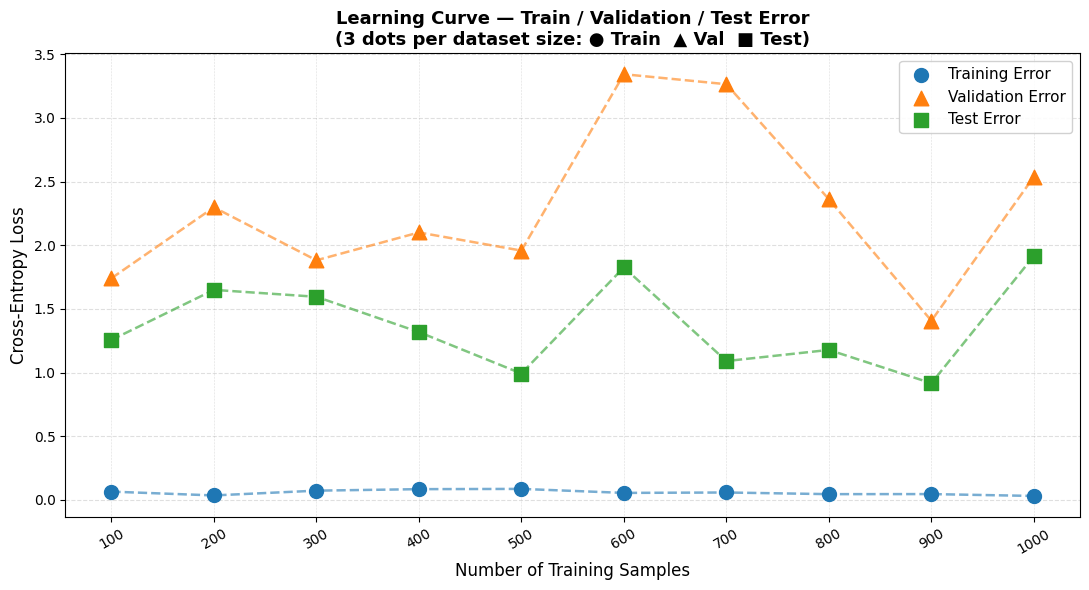

Learning curve saved.


In [17]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(curve_sizes, curve_train, color='#1f77b4', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_val,   color='#ff7f0e', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_test,  color='#2ca02c', linewidth=1.8, linestyle='--', alpha=0.6)

ax.scatter(curve_sizes, curve_train, marker='o', s=100,
           color='#1f77b4', zorder=5, label='Training Error')
ax.scatter(curve_sizes, curve_val,   marker='^', s=110,
           color='#ff7f0e', zorder=5, label='Validation Error')
ax.scatter(curve_sizes, curve_test,  marker='s', s=100,
           color='#2ca02c', zorder=5, label='Test Error')

for s in curve_sizes:
    ax.axvline(s, color='grey', linewidth=0.4, linestyle=':', alpha=0.5)

ax.set_xlabel('Number of Training Samples', fontsize=12)
ax.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax.set_title('Learning Curve — Train / Validation / Test Error\n'
             '(3 dots per dataset size: ● Train  ▲ Val  ■ Test)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.set_xticks(curve_sizes)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('learning_curve.png', dpi=130, bbox_inches='tight')
plt.show()
print('Learning curve saved.')

## 15. Full Training History (Final Model)

In [18]:
history_model, history_opt, history_sch = make_model()
h = {'train_loss': [], 'val_loss': [], 'test_loss': [],
     'train_acc':  [], 'val_acc':  [], 'test_acc':  []}

best_acc_ht   = -1.0
best_state_ht = None
patience_ht   = 0

print(f'Training for up to {NUM_EPOCHS} epochs …\n')
for epoch in range(NUM_EPOCHS):
    tr_l, tr_a = train_one_epoch(history_model, train_loader, history_opt)
    vl_l, vl_a, _, _ = evaluate(history_model, val_loader)
    te_l, te_a, _, _ = evaluate(history_model, test_loader)
    history_sch.step()

    for key, val in zip(
        ['train_loss','val_loss','test_loss','train_acc','val_acc','test_acc'],
        [tr_l, vl_l, te_l, tr_a, vl_a, te_a]
    ):
        h[key].append(val)

    print(f'Ep {epoch+1:02d}/{NUM_EPOCHS}  '
          f'Train L={tr_l:.4f} A={tr_a:.4f} | '
          f'Val L={vl_l:.4f} A={vl_a:.4f} | '
          f'Test L={te_l:.4f} A={te_a:.4f}')

    if vl_a > best_acc_ht:
        best_acc_ht   = vl_a
        patience_ht   = 0
        best_state_ht = {k2: v.cpu() for k2, v in history_model.state_dict().items()}
    else:
        patience_ht += 1
        if patience_ht >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}.')
            break

print(f'\nBest validation accuracy: {best_acc_ht:.4f}')

Training for up to 60 epochs …

Ep 01/60  Train L=0.6184 A=0.7455 | Val L=2.1164 A=0.4035 | Test L=1.8446 A=0.4107
Ep 02/60  Train L=0.2501 A=0.9063 | Val L=2.1281 A=0.5789 | Test L=1.6268 A=0.6250
Ep 03/60  Train L=0.1655 A=0.9353 | Val L=2.0456 A=0.5789 | Test L=1.2372 A=0.5536
Ep 04/60  Train L=0.1026 A=0.9615 | Val L=2.1341 A=0.6140 | Test L=1.2007 A=0.6964
Ep 05/60  Train L=0.0960 A=0.9638 | Val L=2.2774 A=0.6140 | Test L=1.6568 A=0.6786
Ep 06/60  Train L=0.0839 A=0.9679 | Val L=1.9586 A=0.5965 | Test L=1.3442 A=0.6250
Ep 07/60  Train L=0.0884 A=0.9631 | Val L=2.3469 A=0.5965 | Test L=1.3351 A=0.6786
Ep 08/60  Train L=0.0690 A=0.9769 | Val L=2.0939 A=0.5614 | Test L=1.7705 A=0.5893
Ep 09/60  Train L=0.0660 A=0.9769 | Val L=2.2023 A=0.5614 | Test L=1.3118 A=0.6071
Ep 10/60  Train L=0.0618 A=0.9808 | Val L=2.4212 A=0.6140 | Test L=1.8630 A=0.6786
Ep 11/60  Train L=0.0402 A=0.9862 | Val L=3.1543 A=0.6667 | Test L=1.6496 A=0.7143
Ep 12/60  Train L=0.0468 A=0.9857 | Val L=3.0193 A=0.64

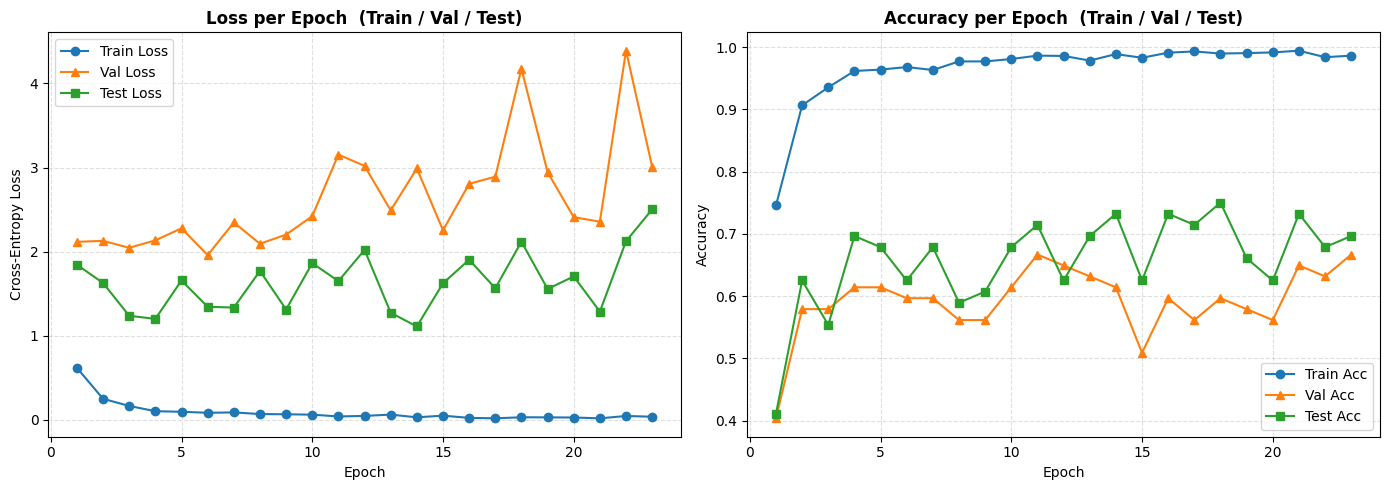

In [19]:
epochs_ran = range(1, len(h['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_ran, h['train_loss'], 'o-', color='#1f77b4', label='Train Loss')
ax1.plot(epochs_ran, h['val_loss'],   '^-', color='#ff7f0e', label='Val Loss')
ax1.plot(epochs_ran, h['test_loss'],  's-', color='#2ca02c', label='Test Loss')
ax1.set_title('Loss per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(); ax1.grid(linestyle='--', alpha=0.4)

ax2.plot(epochs_ran, h['train_acc'], 'o-', color='#1f77b4', label='Train Acc')
ax2.plot(epochs_ran, h['val_acc'],   '^-', color='#ff7f0e', label='Val Acc')
ax2.plot(epochs_ran, h['test_acc'],  's-', color='#2ca02c', label='Test Acc')
ax2.set_title('Accuracy per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend(); ax2.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('training_history.png', dpi=130, bbox_inches='tight')
plt.show()

## 16. Save Model Artifact

In [20]:
save_path = DRIVE_BASE / 'rajuk_resnet18.pth'

artifact = {
    'model_state_dict' : best_state_ht,
    'class_names'      : CLASS_NAMES,
    'image_size'       : IMAGE_SIZE,
    'imagenet_mean'    : IMAGENET_MEAN,
    'imagenet_std'     : IMAGENET_STD,
    'label_source'     : str(source_path),
    'label_column'     : level_col,
    'best_val_acc'     : best_acc_ht,
    'kfold_val_accs'   : fold_val_accs,
    'train_size'       : len(train_dataset),
    'val_size'         : len(val_dataset),
    'test_size'        : len(test_dataset),
    'final_test_acc'   : test_acc,
}

torch.save(artifact, save_path)
print(f'Model saved to  : {save_path}')
print(f'Final test acc  : {test_acc:.4f}')

Model saved to  : /content/drive/MyDrive/ML_Lab/rajuk_resnet18.pth
Final test acc  : 0.6607


## 17. Sanity Check — Predict on Random Test Samples

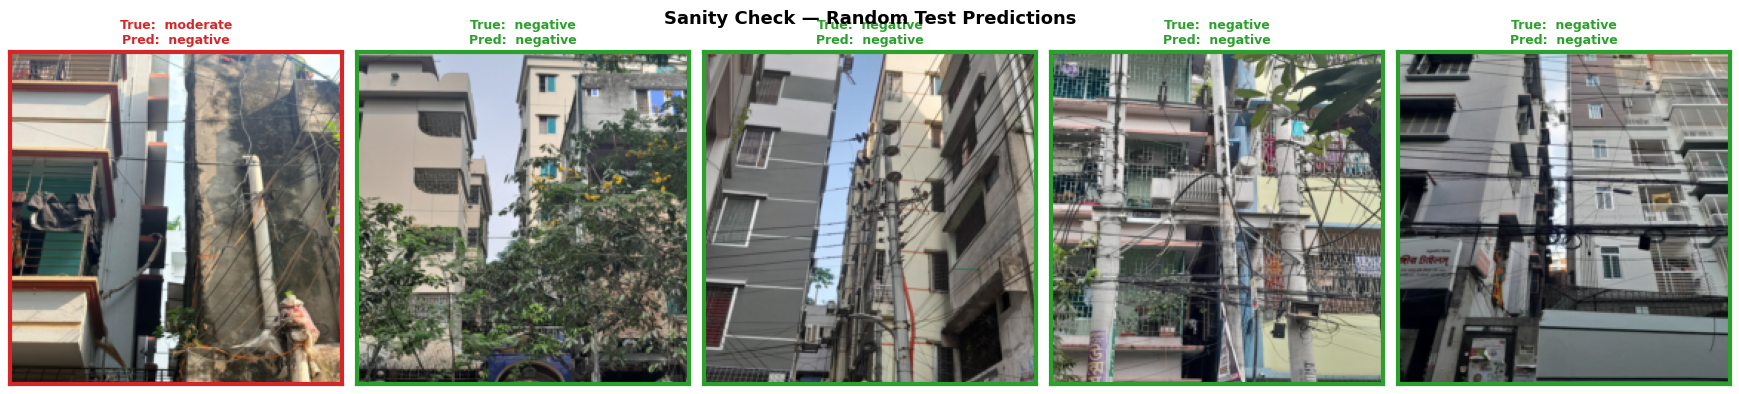

Sanity check complete.


In [21]:
best_model = RajukResNet(len(CLASS_NAMES), dropout=DROPOUT).to(device)
best_model.load_state_dict({k: v.to(device) for k, v in best_state_ht.items()})
best_model.eval()

rng2   = np.random.default_rng(SEED + 1)
sample = rng2.choice(len(test_dataset), size=min(5, len(test_dataset)), replace=False)

fig, axes = plt.subplots(1, len(sample), figsize=(len(sample) * 3.5, 4))
fig.suptitle('Sanity Check — Random Test Predictions', fontsize=13, fontweight='bold')

# Un-normalise for display
inv_mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
inv_std  = torch.tensor(IMAGENET_STD).view(3,1,1)

with torch.no_grad():
    for ax, s_idx in zip(axes, sample):
        img_tensor, true_lbl = test_dataset[int(s_idx)]
        logits   = best_model(img_tensor.unsqueeze(0).to(device))
        pred_lbl = logits.argmax(1).item()

        # Reverse ImageNet normalisation for display
        img_display = (img_tensor * inv_std + inv_mean).clamp(0, 1)
        img_np = img_display.permute(1, 2, 0).numpy()

        ax.imshow(img_np)
        ax.set_xticks([]); ax.set_yticks([])

        colour = '#2ca02c' if pred_lbl == true_lbl else '#d62728'
        ax.set_title(
            f'True:  {CLASS_NAMES[true_lbl]}\nPred:  {CLASS_NAMES[pred_lbl]}',
            fontsize=9, color=colour, fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor(colour); spine.set_linewidth(3)

plt.tight_layout()
plt.savefig('sanity_predictions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sanity check complete.')